# Ejercicios ensembling
En este ejercicio vas a realizar prediciones sobre un dataset de ciudadanos indios diabéticos. Se trata de un problema de clasificación en el que intentaremos predecir 1 (diabético) 0 (no diabético).

### 1. Carga las librerias que consideres comunes al notebook

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

### 2. Lee los datos de [esta direccion](https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv)
Los nombres de columnas son:
```Python
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
```

In [3]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

df = pd.read_csv(url, names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class'], 
                 header= None)

df

,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


### 3. Bagging
Para este apartado tendrás que crear un ensemble utilizando la técnica de bagging ([BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)), mediante la cual combinarás 100 [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html). Recuerda utilizar también [cross validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html) con 10 kfolds.

**Para este apartado y siguientes, no hace falta que dividas en train/test**, por hacerlo más sencillo. Simplemente divide tus datos en features y target.

Establece una semilla

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   preg    768 non-null    int64  
 1   plas    768 non-null    int64  
 2   pres    768 non-null    int64  
 3   skin    768 non-null    int64  
 4   test    768 non-null    int64  
 5   mass    768 non-null    float64
 6   pedi    768 non-null    float64
 7   age     768 non-null    int64  
 8   class   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [9]:
df.describe()

,preg,plas,pres,skin,test,mass,pedi,age,class
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [10]:
df["class"].value_counts()

class
0    500
1    268
Name: count, dtype: int64

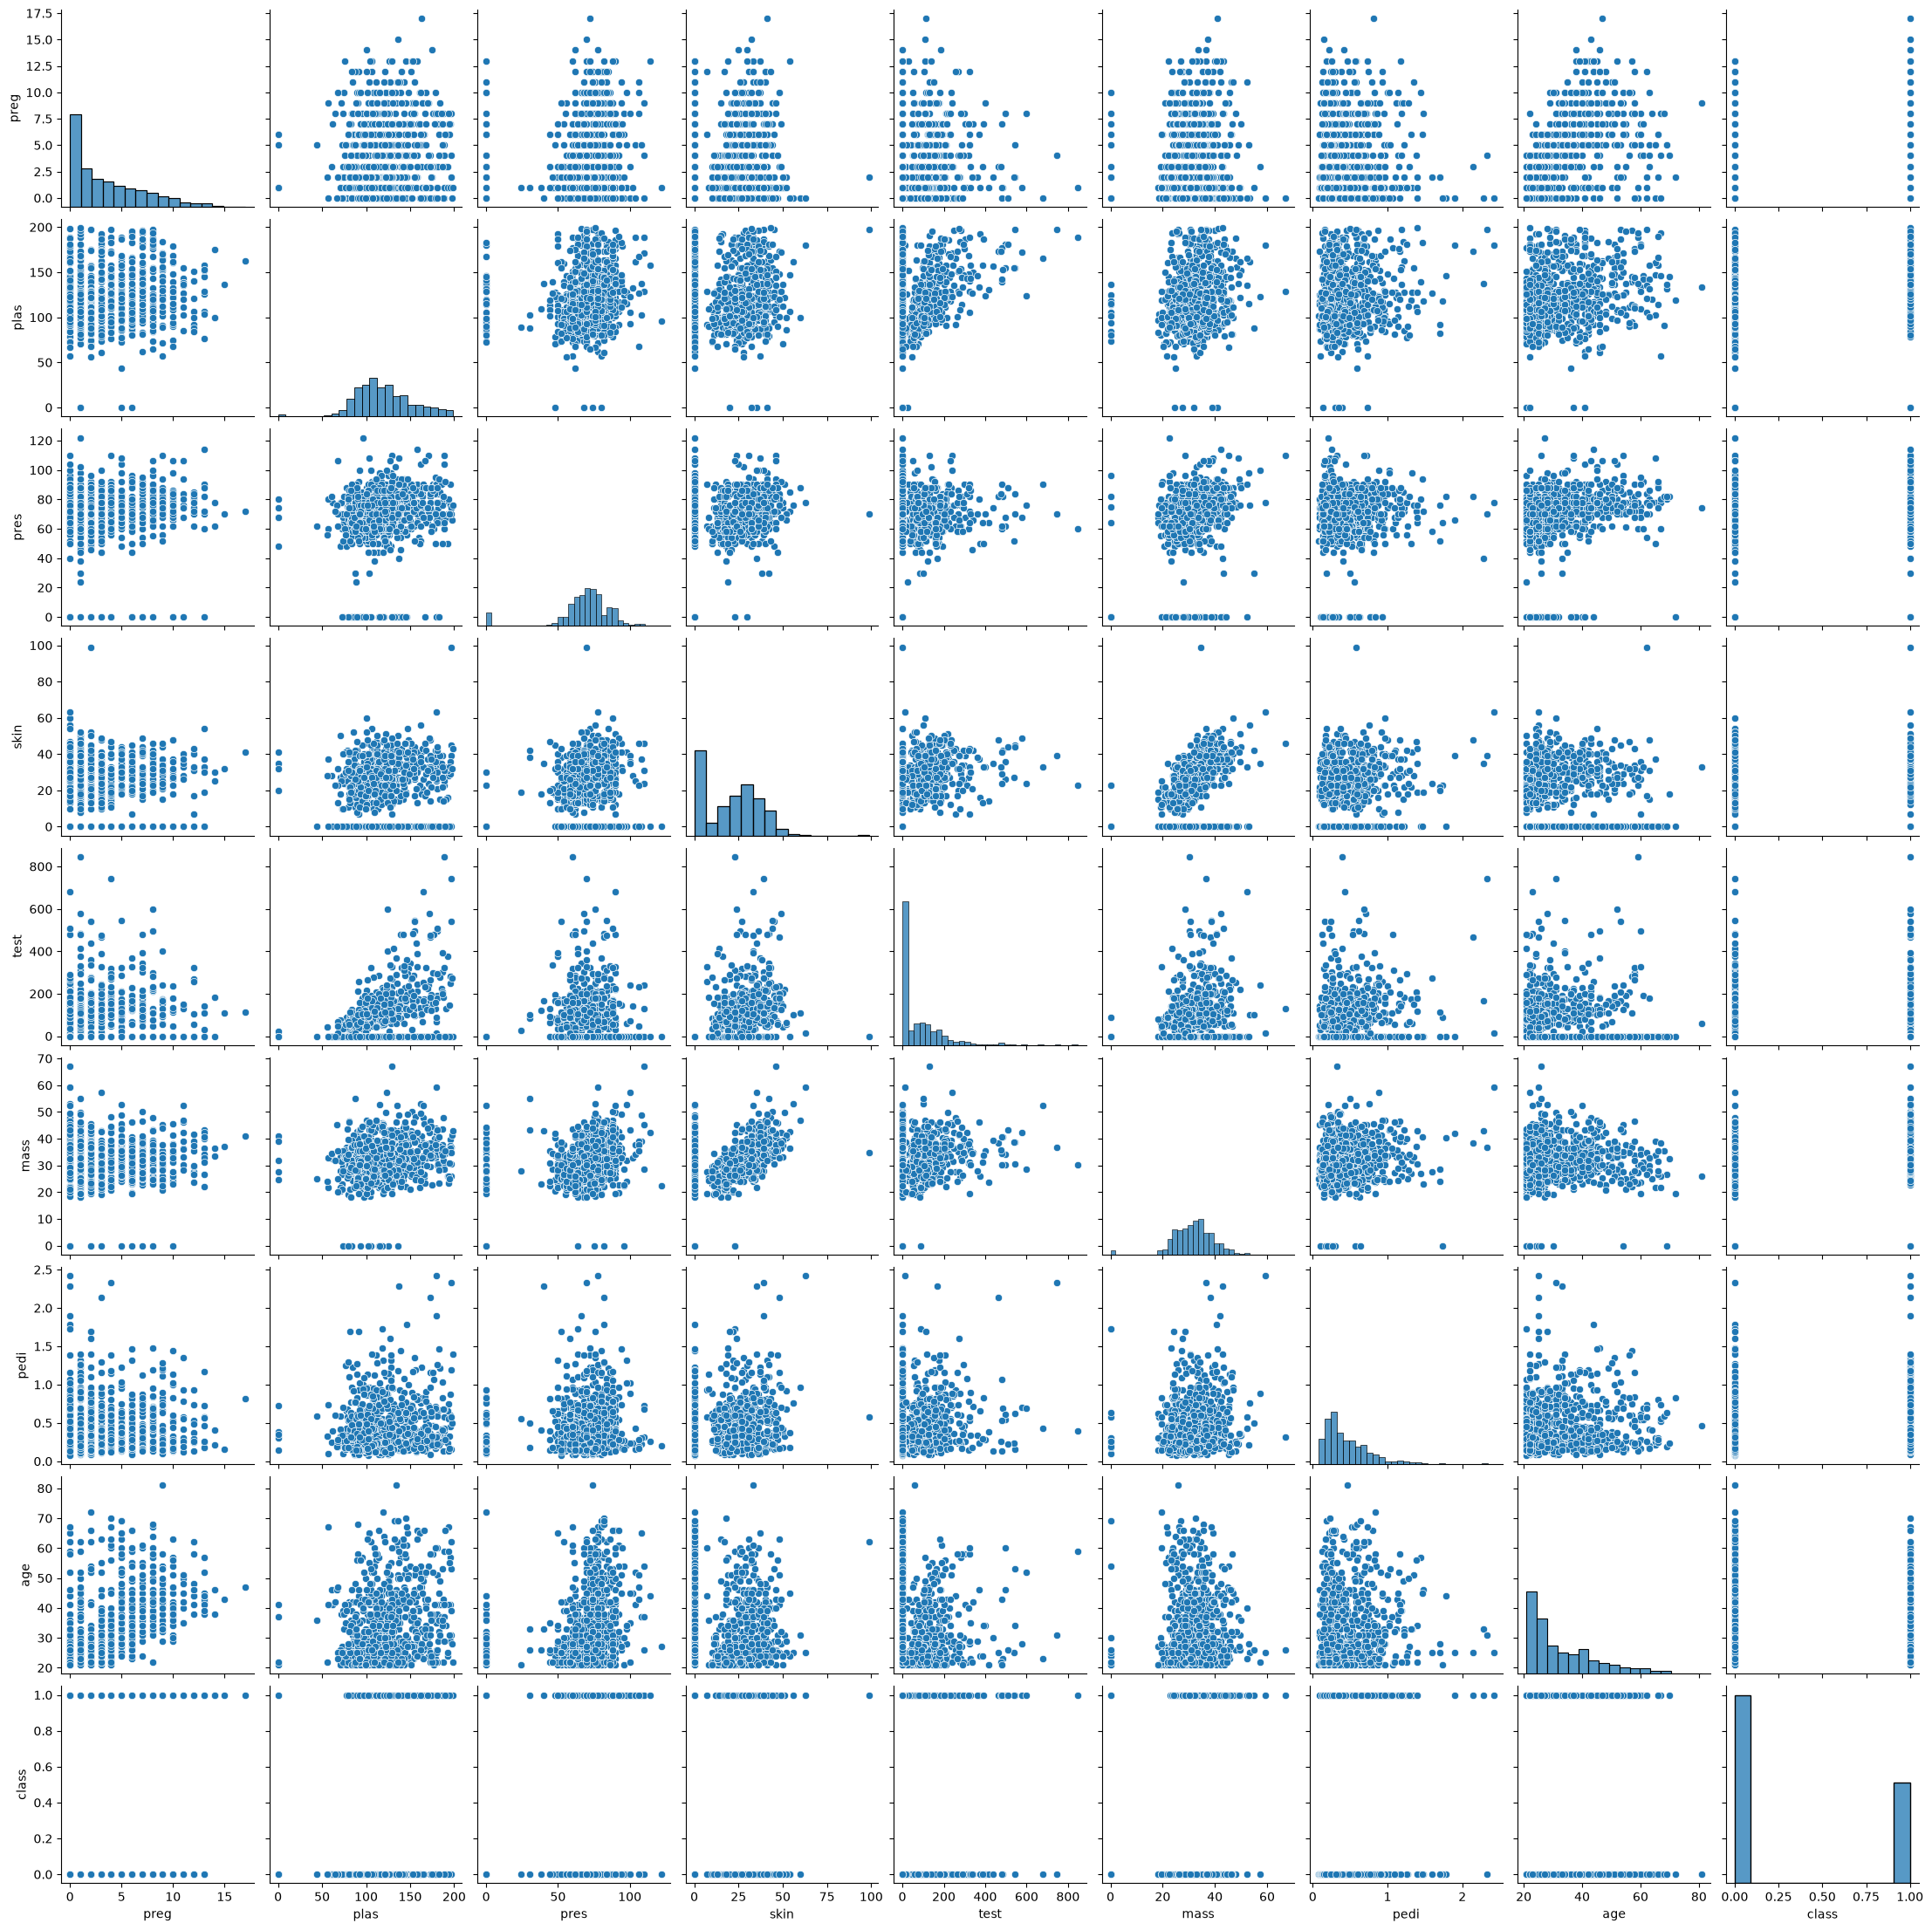

In [4]:
sns.pairplot(df)

<Axes: >

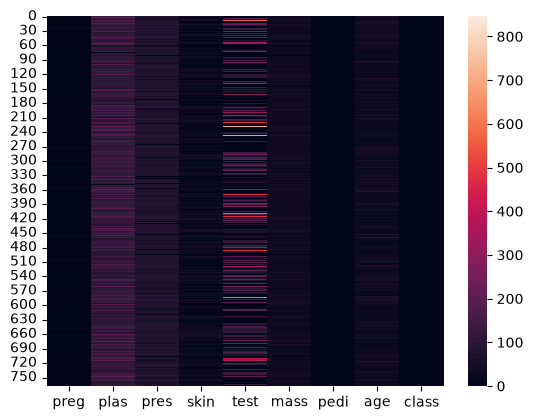

In [5]:
sns.heatmap(df)

In [6]:
X = df.drop(columns="class")
y = df["class"]

In [24]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import model_selection

estimator = DecisionTreeClassifier()

bag_clf = BaggingClassifier(
    estimator = estimator,
    n_estimators= 100, 
    random_state= 42)

resultados_bag = model_selection.cross_val_score(bag_clf, X, y, cv= 10, scoring="recall")
print(resultados_bag)
print(resultados_bag.mean())
print(resultados_bag.std())

[0.59259259 0.59259259 0.74074074 0.55555556 0.40740741 0.62962963
 0.66666667 0.74074074 0.5        0.69230769]
0.6118233618233618
0.10061710468332849


### 4. Random Forest
En este caso entrena un [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) con 100 árboles y un `max_features` de 3. También con validación cruzada

In [25]:
from sklearn.ensemble import RandomForestClassifier

rnd_clf = RandomForestClassifier(n_estimators= 100,
                                 max_features= 3,
                                 random_state= 42)

resultados_rnd = model_selection.cross_val_score(rnd_clf, X, y, cv= 10, scoring="recall")
print(resultados_rnd)
print(resultados_rnd.mean())
print(resultados_rnd.std())

[0.66666667 0.62962963 0.62962963 0.55555556 0.33333333 0.59259259
 0.62962963 0.74074074 0.46153846 0.65384615]
0.5893162393162392
0.10998045887153349


### 5. AdaBoost
Implementa un [AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html) con 30 árboles.

In [32]:
from sklearn.ensemble import AdaBoostClassifier

estimator = DecisionTreeClassifier()

ada_clf = AdaBoostClassifier(estimator = estimator,
                             n_estimators= 30,
                             random_state= 42)

resultados_ada = model_selection.cross_val_score(ada_clf, X, y, cv= 10, scoring="recall")
print(resultados_ada)
print(resultados_ada.mean())
print(resultados_ada.std())

[0.55555556 0.48148148 0.59259259 0.40740741 0.40740741 0.66666667
 0.7037037  0.7037037  0.30769231 0.61538462]
0.5441595441595443
0.13065714678410417


### 6. GradientBoosting
Implementa un [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) con 100 estimadores

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gbrt = GradientBoostingClassifier(n_estimators= 100,
                                 random_state= 42)

resultados_gbrt = model_selection.cross_val_score(gbrt, X, y, cv= 10, scoring="recall")
print(resultados_gbrt)
print(resultados_gbrt.mean())
print(resultados_gbrt.std())                        

[0.66666667 0.55555556 0.66666667 0.51851852 0.37037037 0.7037037
 0.66666667 0.7037037  0.5        0.69230769]
0.6044159544159544
0.10701040157500176


### 7. XGBoost
Para este apartado utiliza un [XGBoostClassifier](https://docs.getml.com/latest/api/getml.predictors.XGBoostClassifier.html) con 100 estimadores. XGBoost no forma parte de la suite de modelos de sklearn, por lo que tendrás que instalarlo con pip install

In [ ]:
import xgboost

xgb_clas = xgboost.XGBClassifier(n_estimators= 100,
                                 random_state= 42)

resultados_xgb = model_selection.cross_val_score(xgb_clas, X, y, cv= 10, scoring="recall")
print(resultados_xgb)
print(resultados_xgb.mean())
print(resultados_xgb.std())   

[0.62962963 0.51851852 0.7037037  0.62962963 0.37037037 0.7037037
 0.59259259 0.74074074 0.46153846 0.61538462]
0.5965811965811966
0.11035758809444107


### 8. Primeros resultados
Crea un dataframe con los resultados y sus algoritmos, ordenándolos de mayor a menor

In [33]:
mean_bag = resultados_bag.mean()
std_bag = resultados_bag.std()

mean_rnd = resultados_rnd.mean()
std_rnd = resultados_rnd.std()

mean_ada = resultados_ada.mean()
std_ada = resultados_ada.std()

mean_gbrt = resultados_gbrt.mean()
std_gbrt = resultados_gbrt.std()

mean_xgb = resultados_xgb.mean()
std_xgb = resultados_xgb.std()

In [44]:
data = {
    "algoritmo": [
        "Bagging",
        "Random Forest max_features=3",
        "AdaBoost n_estimator=30",
        "Gradient Boosting",
        "XGBoost",
    ],
    "media recall": [mean_bag, mean_rnd, mean_ada, mean_gbrt, mean_xgb],
    "desviacion_std": [std_bag, std_rnd, std_ada, std_gbrt, std_xgb],
}

df_resultados = (
    pd.DataFrame(data)
    .sort_values(by="media recall", ascending=False)
    .reset_index(drop=True)
)

print(df_resultados)

                      algoritmo  media recall  desviacion_std
0                       Bagging      0.611823        0.100617
1             Gradient Boosting      0.604416        0.107010
2                       XGBoost      0.596581        0.110358
3  Random Forest max_features=3      0.589316        0.109980
4       AdaBoost n_estimator=30      0.544160        0.130657


### 9. Hiperparametrización
Vuelve a entrenar los modelos de nuevo, pero esta vez dividiendo el conjunto de datos en train/test y utilizando un gridsearch para encontrar los mejores hiperparámetros.

In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [41]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score

In [38]:
modelos = {
    "Bagging": (
        BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=42),
        {"n_estimators": [50, 100, 200]},
    ),
    "Random Forest": (
        RandomForestClassifier(max_features=3, random_state=42),
        {"n_estimators": [50, 100, 200], "max_depth": [None, 5, 10]},
    ),
    "AdaBoost": (
        AdaBoostClassifier(
            estimator=DecisionTreeClassifier(), n_estimators=30, random_state=42
        ),
        {"n_estimators": [30, 50, 100], "learning_rate": [0.1, 0.5, 1.0]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1]},
    ),
    "XGBoost": (
        xgboost.XGBClassifier(random_state=42),
        {"n_estimators": [50, 100, 200], "learning_rate": [0.05, 0.1]},
    ),
}

In [42]:
resultados_grid = []
mejores_modelos = {}

for nombre, (modelo, grid_params) in modelos.items():
    grid = GridSearchCV(
        estimator=modelo,
        param_grid=grid_params,
        cv=10,
        scoring="recall",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)

    # Guardamos el mejor modelo ya reentrenado en X_train
    best_model = grid.best_estimator_
    mejores_modelos[nombre] = best_model

    # Evaluamos en X_test
    y_pred = best_model.predict(X_test)
    test_recall = recall_score(y_test, y_pred)

    resultados_grid.append({
        "algoritmo": nombre,
        "cv_recall_mean": grid.best_score_,
        "test_recall": test_recall,
        "mejores_params": grid.best_params_,
    })

df_grid = pd.DataFrame(resultados_grid).sort_values(
    by="test_recall", ascending=False
)
print(df_grid)

           algoritmo  cv_recall_mean  test_recall  \
2           AdaBoost        0.596104     0.745455   
4            XGBoost        0.652165     0.709091   
3  Gradient Boosting        0.642424     0.690909   
0            Bagging        0.591342     0.672727   
1      Random Forest        0.629004     0.672727   

                                mejores_params  
2   {'learning_rate': 0.1, 'n_estimators': 30}  
4  {'learning_rate': 0.1, 'n_estimators': 100}  
3  {'learning_rate': 0.1, 'n_estimators': 200}  
0                        {'n_estimators': 100}  
1     {'max_depth': None, 'n_estimators': 200}  


### 10. Conclusiones finales

Tras aplicar GridSearchCV y evaluar en test, los modelos de boosting superan a Bagging y Random Forest en recall. AdaBoost (learning_rate=0.1, n_estimators=30) obtiene el mayor test_recall (0.7455), mientras que XGBoost (0.7091) y Gradient Boosting (0.6909) ofrecen un rendimiento muy competitivo y mayor cv_recall_mean (0.6522 y 0.6424). Las diferencias entre cv_recall_mean y test_recall reflejan la variabilidad propia de evaluar sobre una única partición de test frente al promedio de validación cruzada, y conviene complementar el análisis con otras métricas (como precision o F1) para evaluar el impacto de los falsos positivos.